# Lab 1 · Train VGG on CIFAR-10 + mini project: an image classifier

**Course lab:** `CV-Week3-Lecture1.ipynb` (copy in `course-files/labs/`). Exercise: *"Train VGG on CIFAR-10"*. Mini project: *"Image Classifier"*. Plus the course's *"Visualizing VGG Architecture with Graphviz"* cell.

**What you will learn**
- How to load CIFAR-10 with `torchvision`, what `ToTensor()` and `Normalize()` do, and what a `DataLoader` gives you.
- How the course adapts `models.vgg16` to 10 classes by replacing `classifier[6]`.
- The standard PyTorch training loop (`zero_grad → forward → loss → backward → step`), line by line.
- **Why the course's exact recipe (VGG16 from scratch, Adam, lr = 0.001) gets stuck at 10 % accuracy**, and two fixes that work.
- How to evaluate properly (`model.eval()` + `torch.no_grad()`), with per-class accuracy, a confusion matrix and a grid of predictions.

**Run time.** 8 minutes on the 4-core CPU this notebook was built on, which was shared with other heavy jobs at the time (measured: see the last code cell). Most of it is the two VGG16 epochs. An idle machine will be faster. On a Google Colab GPU it should take only a few minutes (estimate), and there you can afford the full 50,000-image training set (see the Colab section at the end).

## 0 · Theory in 60 seconds

Full theory: [notes/02_classic_cnns_lenet_alexnet_vgg.md](../notes/02_classic_cnns_lenet_alexnet_vgg.md) and the notebook [02_classic_cnns_lenet_alexnet_vgg.ipynb](../notebooks/02_classic_cnns_lenet_alexnet_vgg.ipynb), where we build LeNet by hand.

| Year | Model | Remember it for |
|---|---|---|
| 1998 | **LeNet-5** | conv → pool → fully connected; read handwritten digits |
| 2012 | **AlexNet** | won ImageNet; **ReLU, dropout, GPU training** |
| 2014 | **VGG-16/19** | **depth + only 3×3 filters**; 16 weight layers, about 138 million parameters (134 million with a 10-class head) |

**Why 3×3 filters?** Two stacked 3×3 convolutions see a 5×5 area and three see 7×7, with fewer weights than one big filter and an extra ReLU in between. VGG16 = 13 conv layers (in 5 blocks, each ending in a 2×2 max-pool) + 3 fully connected layers.

In [1]:
%matplotlib inline
import os, time, copy, urllib.request
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

# While this notebook was built, other jobs shared the same 4-core CPU, so we limit PyTorch to 2 threads.
# On your own computer you can delete this line: PyTorch then uses all your cores.
torch.set_num_threads(2)
NOTEBOOK_START = time.time()
torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cpu


## 1 · Setup & data loading (the course's first code cell)

**CIFAR-10** = 60,000 tiny colour photos, **32×32 pixels**, 10 classes (plane, car, bird, cat, deer, dog, frog, horse, ship, truck): 50,000 for training and 10,000 for testing, exactly balanced (5,000 + 1,000 per class).

The course's transform, explained:

| Line | What it does |
|---|---|
| `transforms.ToTensor()` | PIL image (H×W×3, values 0–255) → tensor **3×H×W, values 0.0–1.0** (channels first, which PyTorch expects) |
| `transforms.Normalize((0.5,), (0.5,))` | `(x − 0.5) / 0.5` → values in **−1 … 1**, centred on 0, which helps training. The course gives **one** mean and one std; PyTorch reuses that single value for all 3 channels (we check this below). Writing `(0.5, 0.5, 0.5)` is clearer. |
| `DataLoader(..., batch_size=64, shuffle=True)` | hands out **mini-batches of 64 images**; reshuffles the training set every epoch so batches differ |
| `shuffle=False` on the test set | order does not matter for testing, and a fixed order makes results repeatable |

### Two routes to the data (be honest about which one ran)
1. **Official route (what the course uses):** `torchvision.datasets.CIFAR10(root='./data', download=True)` downloads the 163 MB archive from the University of Toronto. This works on a normal internet connection, e.g. your laptop or Colab.
2. **Fallback route:** the machine this notebook was built on cannot reach that server. So if the download fails, we fetch the **same CIFAR-10 images, saved as individual JPG files**, from a public GitHub mirror (`YoongiKim/CIFAR-10-images`, folders `train/<class>/0000.jpg …`, 5,000 per class for training and 1,000 per class for testing). The JPGs are very slightly compressed, which makes no visible difference.

**Subset.** Training on the full 50,000 images is fine on a GPU but slow on a CPU. Either way we use the **first 500 training and 100 test images per class (5,000 + 1,000, still perfectly balanced)**. Set `N_TRAIN_PER_CLASS = 5000` and `N_TEST_PER_CLASS = 1000` on a GPU to use everything.

In [2]:
N_TRAIN_PER_CLASS = 500     # full dataset: 5000
N_TEST_PER_CLASS = 100      # full dataset: 1000
DIR_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']  # CIFAR-10 label order
MIRROR = "https://raw.githubusercontent.com/YoongiKim/CIFAR-10-images/master"


def first_n_per_class(targets, n):
    """Indices of the first n images of every class (keeps the subset balanced)."""
    idx, seen = [], {}
    for i, t in enumerate(targets):
        if seen.get(t, 0) < n:
            idx.append(i)
            seen[t] = seen.get(t, 0) + 1
    return idx


class CifarJpgFolder(torch.utils.data.Dataset):
    """Fallback dataset: reads data/cifar10_jpg/<split>/<class>/0000.jpg ... like CIFAR10 would."""
    def __init__(self, root, n_per_class, transform=None):
        self.samples = [(f"{root}/{c}/{i:04d}.jpg", label)
                        for label, c in enumerate(DIR_NAMES) for i in range(n_per_class)]
        self.targets = [label for _, label in self.samples]
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        return (self.transform(img) if self.transform else img), label


def download_mirror(split, n_per_class, root="./data/cifar10_jpg"):
    jobs = [(f"{MIRROR}/{split}/{c}/{i:04d}.jpg", f"{root}/{split}/{c}/{i:04d}.jpg")
            for c in DIR_NAMES for i in range(n_per_class)]
    jobs = [(u, p) for u, p in jobs if not os.path.exists(p)]          # skip files we already have
    def fetch(job):
        url, path = job
        os.makedirs(os.path.dirname(path), exist_ok=True)
        for attempt in range(3):
            try:
                urllib.request.urlretrieve(url, path + ".part")
                os.replace(path + ".part", path)
                return
            except Exception as e:
                err = e
        raise err
    t = time.time()
    with ThreadPoolExecutor(32) as pool:                               # 32 small downloads at a time
        list(pool.map(fetch, jobs))
    print(f"  mirror: {split}: downloaded {len(jobs)} new files in {time.time() - t:.0f}s")
    return f"{root}/{split}"


def load_cifar10(train_transform, test_transform):
    try:
        trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
        testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)
        trainset = torch.utils.data.Subset(trainset, first_n_per_class(trainset.targets, N_TRAIN_PER_CLASS))
        testset = torch.utils.data.Subset(testset, first_n_per_class(testset.targets, N_TEST_PER_CLASS))
        print("DATA ROUTE: official torchvision CIFAR10 download")
    except Exception as e:
        print("Official CIFAR-10 download failed:", type(e).__name__, str(e)[:80])
        print("DATA ROUTE: fallback = CIFAR-10 JPG mirror on GitHub")
        trainset = CifarJpgFolder(download_mirror("train", N_TRAIN_PER_CLASS), N_TRAIN_PER_CLASS, train_transform)
        testset = CifarJpgFolder(download_mirror("test", N_TEST_PER_CLASS), N_TEST_PER_CLASS, test_transform)
    return trainset, testset


# ---- the course's cell, unchanged apart from the loader function ----
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset, testset = load_cifar10(transform, transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(f"train: {len(trainset)} images | test: {len(testset)} images | batches per epoch: {len(trainloader)}")

Official CIFAR-10 download failed: URLError <urlopen error Tunnel connection failed: 403 Forbidden>
DATA ROUTE: fallback = CIFAR-10 JPG mirror on GitHub


  mirror: train: downloaded 4000 new files in 25s


  mirror: test: downloaded 500 new files in 3s
train: 5000 images | test: 1000 images | batches per epoch: 79


Let's check what one batch looks like and confirm that the single-value `Normalize` really treats all three channels the same.

one batch of images: (64, 3, 32, 32)  -> (batch, channels, height, width)
one batch of labels: (64,) [2, 6, 1, 2, 3, 5, 2, 3, 8, 5]
pixel range after Normalize: -1.00 … 1.00
Normalize((0.5,),(0.5,)) == Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)) ? True
training images per class: {'plane': 500, 'car': 500, 'bird': 500, 'cat': 500, 'deer': 500, 'dog': 500, 'frog': 500, 'horse': 500, 'ship': 500, 'truck': 500}


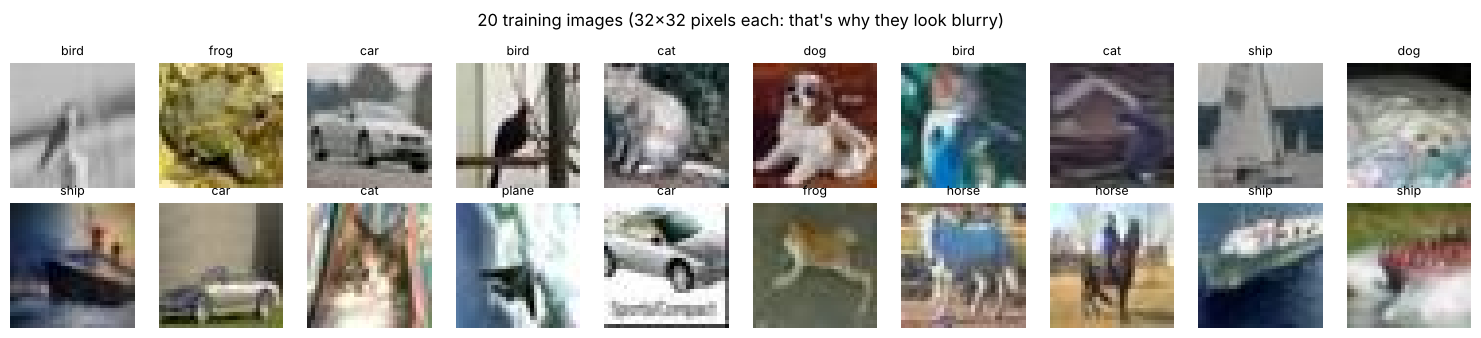

In [3]:
images, labels = next(iter(trainloader))
print("one batch of images:", tuple(images.shape), " -> (batch, channels, height, width)")
print("one batch of labels:", tuple(labels.shape), labels[:10].tolist())
print(f"pixel range after Normalize: {images.min():.2f} … {images.max():.2f}")

img = Image.open(trainset.samples[0][0]) if hasattr(trainset, "samples") else Image.fromarray(trainset.dataset.data[trainset.indices[0]])
a = transforms.Normalize((0.5,), (0.5,))(transforms.ToTensor()(img))
b = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))(transforms.ToTensor()(img))
print("Normalize((0.5,),(0.5,)) == Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)) ?", torch.equal(a, b))

counts = np.bincount(np.array(trainset.targets if hasattr(trainset, "targets") else [trainset.dataset.targets[i] for i in trainset.indices]), minlength=10)
print("training images per class:", dict(zip(classes, counts.tolist())))

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for ax, im, lab in zip(axes.ravel(), images[:20], labels[:20]):
    ax.imshow((im / 2 + 0.5).permute(1, 2, 0).clamp(0, 1))      # un-normalise: x*0.5 + 0.5
    ax.set_title(classes[lab], fontsize=9); ax.axis("off")
plt.suptitle("20 training images (32×32 pixels each: that's why they look blurry)")
plt.tight_layout(); plt.show()

## 2 · Exercise: Train VGG on CIFAR-10

### 2.1 Building the model: the course's three key lines

```python
vgg16 = models.vgg16(pretrained=False)         # course (old API)
vgg16.classifier[6] = nn.Linear(4096, 10)      # adjust output layer
```

- **`models.vgg16(...)`** builds the VGG16 architecture. `pretrained=False` means **random weights** (training from scratch). In current torchvision `pretrained=` is **deprecated**: the modern spelling is **`weights=None`** (random) or `weights=models.VGG16_Weights.IMAGENET1K_V1` (ImageNet-trained). It is deprecated rather than removed, so the old spelling still works but prints a warning.
- **`vgg16.classifier`** is the fully connected part: `[Linear(25088→4096), ReLU, Dropout, Linear(4096→4096), ReLU, Dropout, Linear(4096→1000)]`. Index **6** is the last layer with **1000 outputs** (ImageNet's 1000 classes). We swap it for a new `nn.Linear(4096, 10)`, one output score per CIFAR-10 class.

In [4]:
vgg16 = models.vgg16(weights=None)                 # = pretrained=False in the course
print("before:", vgg16.classifier[6])
vgg16.classifier[6] = nn.Linear(4096, 10)          # adjust output layer: 1000 ImageNet classes -> 10 CIFAR classes
print("after: ", vgg16.classifier[6])
print()
print(vgg16.classifier)

def count_params(m):
    return sum(p.numel() for p in m.parameters())
n_feat, n_cls = count_params(vgg16.features), count_params(vgg16.classifier)
print(f"\nparameters: features (13 conv layers) = {n_feat/1e6:.1f} M | classifier (3 FC layers) = {n_cls/1e6:.1f} M | total = {(n_feat+n_cls)/1e6:.1f} M")

before: Linear(in_features=4096, out_features=1000, bias=True)
after:  Linear(in_features=4096, out_features=10, bias=True)

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=10, bias=True)
)

parameters: features (13 conv layers) = 14.7 M | classifier (3 FC layers) = 119.6 M | total = 134.3 M


### 2.2 VGG16 was designed for 224×224 images, not 32×32

VGG16 has **5 max-pool layers**, and each one halves the image size. A 224×224 photo becomes **7×7** at the end of `features`. A 32×32 CIFAR image becomes **1×1**. VGG then has an `AdaptiveAvgPool2d((7, 7))` that forces a 7×7 output whatever the input size. With a 1×1 input it simply **copies the same number 49 times**, so the first Linear layer gets 25,088 inputs containing only 512 different values. It still *runs* (no shape error), but it is very wasteful. Let's prove it:

In [5]:
x = torch.randn(1, 3, 32, 32)
with torch.no_grad():
    f = vgg16.features(x)
    p = vgg16.avgpool(f)
print("32x32 input  -> after features:", tuple(f.shape), "-> after avgpool:", tuple(p.shape), "-> flattened:", p.flatten(1).shape[1])
print("all 49 values in each 7x7 map identical?", torch.allclose(p, p[:, :, :1, :1].expand_as(p)))
with torch.no_grad():
    print("224x224 input -> after features:", tuple(vgg16.features(torch.randn(1, 3, 224, 224)).shape))
print(f"\n{n_cls/(n_feat+n_cls):.0%} of VGG16's parameters sit in the classifier, mostly in Linear(25088 -> 4096) = {25088*4096/1e6:.0f} M weights")

32x32 input  -> after features: (1, 512, 1, 1) -> after avgpool: (1, 512, 7, 7) -> flattened: 25088
all 49 values in each 7x7 map identical? True
224x224 input -> after features: (1, 512, 7, 7)

89% of VGG16's parameters sit in the classifier, mostly in Linear(25088 -> 4096) = 103 M weights


### 2.3 The training loop, line by line (the course's code)

```python
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vgg16.parameters(), lr=0.001)
```
- **`nn.CrossEntropyLoss()`**: the standard loss for classification. It takes the 10 raw scores ("logits"), turns them into probabilities with softmax and returns **−log(probability of the correct class)**. Perfect guess → 0. A random guess among 10 classes → −log(1/10) = **2.303**. Remember that number!
- **`optim.Adam(..., lr=0.001)`**: Adam is gradient descent with a separate, self-adjusting step size for every weight. `lr` (learning rate) = how big the steps are. 0.001 is Adam's usual default.

Inside the loop, for every mini-batch:

| Line | Meaning |
|---|---|
| `inputs, labels = inputs.to(device), labels.to(device)` | move the batch to the GPU if there is one (model and data must be on the same device) |
| `optimizer.zero_grad()` | wipe the gradients from the previous batch (PyTorch **adds** gradients up by default) |
| `outputs = vgg16(inputs)` | **forward pass**: 64 images → 64×10 scores |
| `loss = criterion(outputs, labels)` | how wrong were we on this batch? |
| `loss.backward()` | **backpropagation**: compute the gradient of the loss for every weight |
| `optimizer.step()` | update every weight a little in the direction that lowers the loss |
| `running_loss += loss.item()` | `.item()` turns the 1-element tensor into a plain Python number for printing |

One **epoch** = one pass over all training batches. The course trains for `range(1, 3)` = **2 epochs**. A VGG16 epoch takes several minutes on our CPU, so we run **1 epoch** and also record the loss of every batch so we can plot it.

In [6]:
torch.manual_seed(0)
vgg16 = models.vgg16(weights=None)
vgg16.classifier[6] = nn.Linear(4096, 10)  # adjust output layer
vgg16.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vgg16.parameters(), lr=0.001)

batch_losses_course = []
t0 = time.time()
for epoch in range(1, 2):  # course: range(1, 3) = 2 epochs; we run 1 to save CPU time
    vgg16.train()                              # training mode (dropout on); the course relies on the default
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = vgg16(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        batch_losses_course.append(loss.item())
    print(f"Epoch {epoch}, Loss: {running_loss/len(trainloader):.4f}")
time_vgg_epoch = time.time() - t0
print(f"time for 1 epoch of VGG16 on {len(trainset)} images: {time_vgg_epoch:.0f}s")
print(f"largest batch loss: {max(batch_losses_course):.1f} (batch {int(np.argmax(batch_losses_course)) + 1})")
print("loss of the last 10 batches:", np.round(batch_losses_course[-10:], 3))

Epoch 1, Loss: 3.2624
time for 1 epoch of VGG16 on 5000 images: 134s
largest batch loss: 78.0 (batch 2)
loss of the last 10 batches: [2.301 2.306 2.311 2.303 2.301 2.303 2.303 2.305 2.308 2.306]


### 2.4 Evaluate it: the course's "Mini Project" test loop

`torch.max(outputs, 1)` returns `(largest score, its index)` along dimension 1 (the 10 classes). The index **is** the predicted class. We add **`model.eval()`**, which the course forgets (more on that in section 4).

In [7]:
def evaluate(model, loader):
    """Course's test loop + model.eval(). Returns accuracy in % and all predictions/labels."""
    model.eval()                                  # dropout off, batch-norm uses its stored statistics
    correct, total, all_pred, all_true = 0, 0, [], []
    with torch.no_grad():                         # no gradients needed for testing: faster, less memory
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_pred.append(predicted.cpu()); all_true.append(labels.cpu())
    return 100 * correct / total, torch.cat(all_pred).numpy(), torch.cat(all_true).numpy()

acc_course, pred_course, _ = evaluate(vgg16, testloader)
print(f"Accuracy on CIFAR-10 test set: {acc_course:.2f}%")
print("how often each class was predicted:", dict(zip(classes, np.bincount(pred_course, minlength=10).tolist())))

# Look inside: what does the network output for 64 different test images?
vgg16.eval()
with torch.no_grad():
    x, _ = next(iter(testloader))
    feats = vgg16.features(x.to(device))             # output of the last conv block (after ReLU + pool)
    out = vgg16(x.to(device))
print(f"\nfraction of the 512 conv features that are exactly 0 (dead ReLUs): {(feats == 0).float().mean():.1%}")
print("scores for image 0:", np.round(out[0].cpu().numpy(), 3))
print("scores for image 1:", np.round(out[1].cpu().numpy(), 3))
print(f"largest difference between the scores of any two images: {(out - out[0]).abs().max():.6f}")

Accuracy on CIFAR-10 test set: 10.00%
how often each class was predicted: {'plane': 0, 'car': 0, 'bird': 0, 'cat': 0, 'deer': 0, 'dog': 0, 'frog': 0, 'horse': 1000, 'ship': 0, 'truck': 0}



fraction of the 512 conv features that are exactly 0 (dead ReLUs): 100.0%
scores for image 0: [ 0.019  0.009  0.029  0.013  0.002  0.003  0.024  0.032 -0.034  0.01 ]
scores for image 1: [ 0.019  0.009  0.029  0.013  0.002  0.003  0.024  0.032 -0.034  0.01 ]
largest difference between the scores of any two images: 0.000000


**What happened?** Read the outputs above:
- In the first few batches the loss **jumps far above 2.3** (the "largest batch loss" line). Those early Adam steps were far too big.
- After that the loss sits at **≈ 2.303 = −ln(1/10)** for the rest of the epoch: the network is guessing.
- **100 % of the 512 features** coming out of the conv layers are exactly 0, so every image produces **identical scores**, and the model predicts **the same class for all 1,000 test images**. Test accuracy = **10 % = chance**.

**Why?** VGG16 (the original, without batch normalisation) is 16 layers deep with 134 M random weights. Adam with lr = 0.001 took steps that were too large for it. In the first batches the weights were pushed so far that every ReLU in the last conv block outputs zero (**"dead ReLUs"**). A ReLU that outputs 0 also passes back a gradient of 0, so the conv layers can no longer learn and the network is stuck with a constant guess. It never recovers. The original VGG authors needed a careful setup (small learning rate with SGD, and initialising the deeper nets from a shallower trained one). This is not a bug in your code: it is a **real training failure**, and a classic viva question.

### 2.5 Fix 1: same VGG16, smaller learning rate (lr = 0.0001)

In [8]:
def train_epochs(model, optimizer, loader, epochs, scheduler=None, log=True):
    """The course's training loop wrapped in a function. Records batch losses and time per epoch."""
    criterion = nn.CrossEntropyLoss()
    batch_losses, epoch_times = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        t0, running_loss = time.time(), 0.0
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            batch_losses.append(loss.item())
        if scheduler is not None:
            scheduler.step()
        epoch_times.append(time.time() - t0)
        if log:
            print(f"Epoch {epoch}, Loss: {running_loss/len(loader):.4f}  ({epoch_times[-1]:.0f}s)")
    return batch_losses, epoch_times

torch.manual_seed(0)
vgg16_lr4 = models.vgg16(weights=None)
vgg16_lr4.classifier[6] = nn.Linear(4096, 10)
vgg16_lr4.to(device)
batch_losses_lr4, _ = train_epochs(vgg16_lr4, optim.Adam(vgg16_lr4.parameters(), lr=0.0001), trainloader, epochs=1)
acc_lr4, pred_lr4, _ = evaluate(vgg16_lr4, testloader)
print(f"VGG16, Adam lr=0.0001, 1 epoch -> test accuracy {acc_lr4:.2f}%")
print("how often each class was predicted:", dict(zip(classes, np.bincount(pred_lr4, minlength=10).tolist())))

Epoch 1, Loss: 2.1989  (138s)


VGG16, Adam lr=0.0001, 1 epoch -> test accuracy 17.50%
how often each class was predicted: {'plane': 0, 'car': 80, 'bird': 0, 'cat': 435, 'deer': 0, 'dog': 3, 'frog': 0, 'horse': 35, 'ship': 447, 'truck': 0}


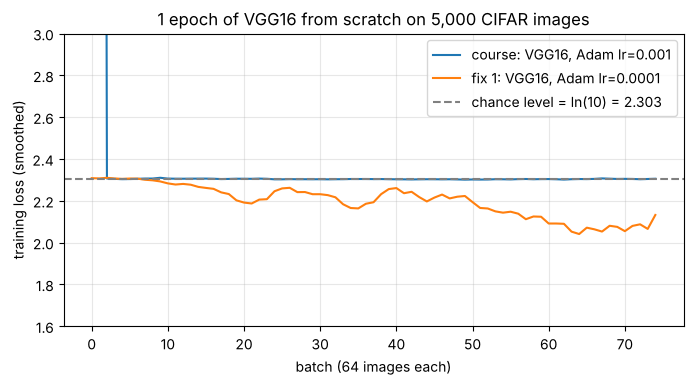

In [9]:
def smooth(v, k=5):
    return np.convolve(v, np.ones(k) / k, mode="valid")

plt.figure(figsize=(8, 3.8))
plt.plot(smooth(batch_losses_course), label="course: VGG16, Adam lr=0.001")
plt.plot(smooth(batch_losses_lr4), label="fix 1: VGG16, Adam lr=0.0001")
plt.axhline(np.log(10), color="gray", ls="--", label="chance level = ln(10) = 2.303")
plt.xlabel("batch (64 images each)"); plt.ylabel("training loss (smoothed)")
plt.title("1 epoch of VGG16 from scratch on 5,000 CIFAR images")
plt.ylim(1.6, 3.0); plt.legend(); plt.grid(alpha=0.3); plt.show()

With the smaller learning rate the loss **drops below 2.303**: VGG16 is learning. But it's slow: one epoch takes minutes on a CPU, and 134 M parameters is a lot for 5,000 tiny images. VGG16 was built for 224×224 ImageNet photos.

### 2.6 Fix 2: a small VGG-style network for 32×32 images

We keep **VGG's design rules** (stacks of 3×3 convolutions with padding 1, then 2×2 max-pool, doubling the channels after every pool, then fully connected layers with dropout) but size it for 32×32 input:

```
32×32×3 → [conv3x3 32, conv3x3 32, pool] → 16×16×32 → [conv 64, conv 64, pool] → 8×8×64
        → [conv 128, conv 128, pool] → 4×4×128 = 2048 values → FC 256 → FC 10
```

Two modern additions:
- **`BatchNorm2d`** after every convolution: it re-centres and re-scales each layer's outputs, which keeps training stable even with lr = 0.001 (this is exactly what `models.vgg16_bn` adds to VGG16).
- **Data augmentation** for training only: `RandomCrop(32, padding=4)` (shift the image by up to 4 pixels) and `RandomHorizontalFlip()` (mirror it). The network sees slightly different versions every epoch, so it memorises less (**less overfitting**). The test images are **not** augmented.

We also use a **cosine learning-rate schedule**: the learning rate starts at 0.001 and is smoothly lowered towards 0 by the last epoch, which helps the final epochs settle.

In [10]:
def conv_bn_relu(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]

class SmallVGG(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            *conv_bn_relu(3, 32),   *conv_bn_relu(32, 32),   nn.MaxPool2d(2),   # 32x32 -> 16x16
            *conv_bn_relu(32, 64),  *conv_bn_relu(64, 64),   nn.MaxPool2d(2),   # 16x16 -> 8x8
            *conv_bn_relu(64, 128), *conv_bn_relu(128, 128), nn.MaxPool2d(2),   # 8x8   -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                   # 128 x 4 x 4 = 2048 numbers
            nn.Dropout(0.5), nn.Linear(2048, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),        # augmentation: random shift
    transforms.RandomHorizontalFlip(),           # augmentation: random mirror
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
trainset_aug, _ = load_cifar10(train_transform, transform)           # same images, augmented on the fly
trainloader_aug = torch.utils.data.DataLoader(trainset_aug, batch_size=64, shuffle=True)

small = SmallVGG().to(device)
print(f"SmallVGG parameters: {count_params(small)/1e6:.2f} M  (VGG16: {count_params(vgg16)/1e6:.1f} M, {count_params(vgg16)/count_params(small):.0f}x more)")

Official CIFAR-10 download failed: URLError <urlopen error Tunnel connection failed: 403 Forbidden>
DATA ROUTE: fallback = CIFAR-10 JPG mirror on GitHub
  mirror: train: downloaded 0 new files in 0s
  mirror: test: downloaded 0 new files in 0s
SmallVGG parameters: 0.82 M  (VGG16: 134.3 M, 165x more)


In [11]:
EPOCHS_SMALL = 15
torch.manual_seed(0)
small = SmallVGG().to(device)
optimizer = optim.Adam(small.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_SMALL)

history = {"train_loss": [], "test_acc": []}
t_start = time.time()
for epoch in range(1, EPOCHS_SMALL + 1):
    losses, times = train_epochs(small, optimizer, trainloader_aug, epochs=1, log=False)
    scheduler.step()
    acc, _, _ = evaluate(small, testloader)
    history["train_loss"].append(np.mean(losses)); history["test_acc"].append(acc)
    print(f"Epoch {epoch:2d}, Loss: {np.mean(losses):.4f}, test accuracy: {acc:5.1f}%  ({times[0]:.0f}s)")
time_small_total = time.time() - t_start
print(f"total: {time_small_total:.0f}s = {time_small_total/EPOCHS_SMALL:.1f}s per epoch")

Epoch  1, Loss: 2.0017, test accuracy:  38.6%  (10s)


Epoch  2, Loss: 1.7653, test accuracy:  40.9%  (10s)


Epoch  3, Loss: 1.6293, test accuracy:  35.5%  (10s)


Epoch  4, Loss: 1.5748, test accuracy:  40.5%  (11s)


Epoch  5, Loss: 1.5127, test accuracy:  48.9%  (10s)


...

Epoch 11, Loss: 1.1683, test accuracy:  58.3%  (10s)


Epoch 12, Loss: 1.1256, test accuracy:  59.0%  (10s)


Epoch 13, Loss: 1.0767, test accuracy:  60.4%  (10s)


Epoch 14, Loss: 1.0512, test accuracy:  61.7%  (11s)


Epoch 15, Loss: 1.0425, test accuracy:  62.2%  (11s)
total: 167s = 11.2s per epoch


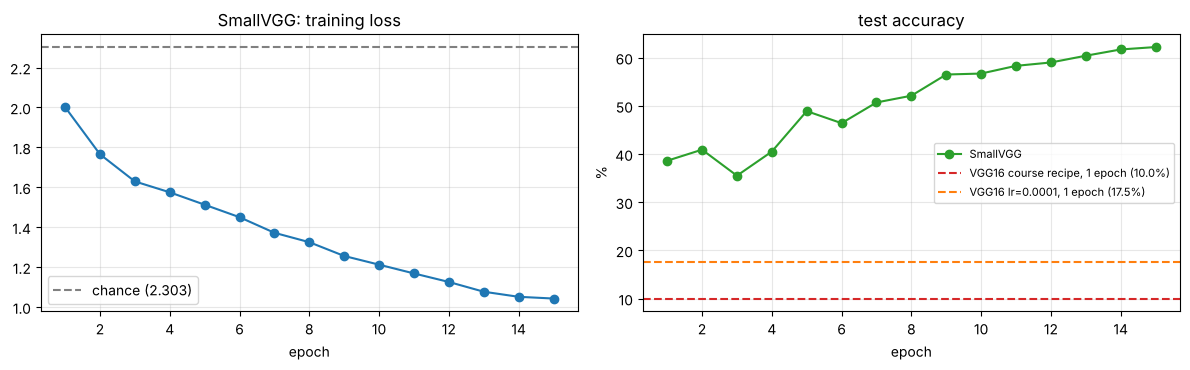

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ep = range(1, EPOCHS_SMALL + 1)
ax[0].plot(ep, history["train_loss"], "o-"); ax[0].axhline(np.log(10), color="gray", ls="--", label="chance (2.303)")
ax[0].set_title("SmallVGG: training loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, history["test_acc"], "o-", color="C2", label="SmallVGG")
ax[1].axhline(acc_course, color="C3", ls="--", label=f"VGG16 course recipe, 1 epoch ({acc_course:.1f}%)")
ax[1].axhline(acc_lr4, color="C1", ls="--", label=f"VGG16 lr=0.0001, 1 epoch ({acc_lr4:.1f}%)")
ax[1].set_title("test accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3 · Mini project: the image classifier, evaluated properly

A single accuracy number hides a lot. A good evaluation also asks: **which classes are easy, which are hard, and what gets confused with what?**

SmallVGG accuracy on the test set: 62.20%  (622 / 1000)

per-class accuracy:
  plane   59.0%  ##############################
  car     83.0%  ##########################################
  bird    45.0%  ######################
  cat     34.0%  #################
  deer    39.0%  ####################
  dog     53.0%  ##########################
  frog    78.0%  #######################################
  horse   73.0%  ####################################
  ship    79.0%  ########################################
  truck   79.0%  ########################################


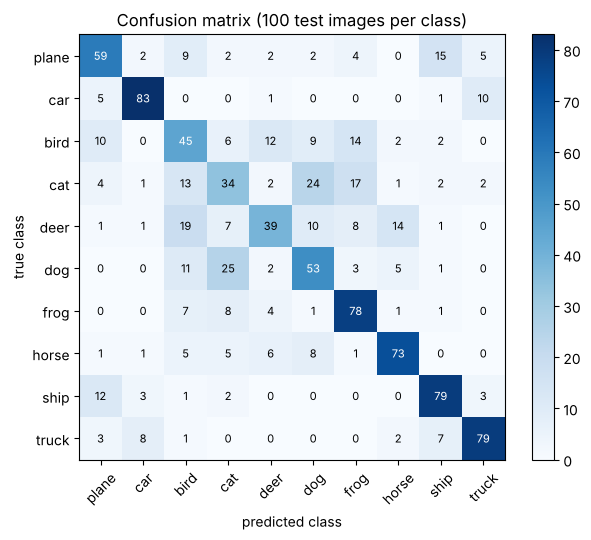

most common mistake: true 'dog' predicted as 'cat' (25 times)


In [13]:
acc_small, pred, true = evaluate(small, testloader)
print(f"SmallVGG accuracy on the test set: {acc_small:.2f}%  ({(pred == true).sum()} / {len(true)})\n")
print("per-class accuracy:")
for i, c in enumerate(classes):
    m = true == i
    print(f"  {c:6s} {100 * (pred[m] == i).mean():5.1f}%  " + "#" * int(round(50 * (pred[m] == i).mean())))

cm = np.zeros((10, 10), dtype=int)
for t, p in zip(true, pred):
    cm[t, p] += 1
plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10), classes, rotation=45); plt.yticks(range(10), classes)
plt.xlabel("predicted class"); plt.ylabel("true class"); plt.title("Confusion matrix (100 test images per class)")
plt.colorbar(fraction=0.046); plt.tight_layout(); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"most common mistake: true '{classes[i]}' predicted as '{classes[j]}' ({off[i, j]} times)")

### Predicting on a batch of test images (the course's last cell, fixed)

The course runs `outputs = vgg16(images.to(device))` **outside** `torch.no_grad()` and without `eval()`. That wastes memory building a gradient graph nobody uses, and leaves dropout switched on. We do it properly and show 16 images with **true** and **predicted** labels (green = right, red = wrong).

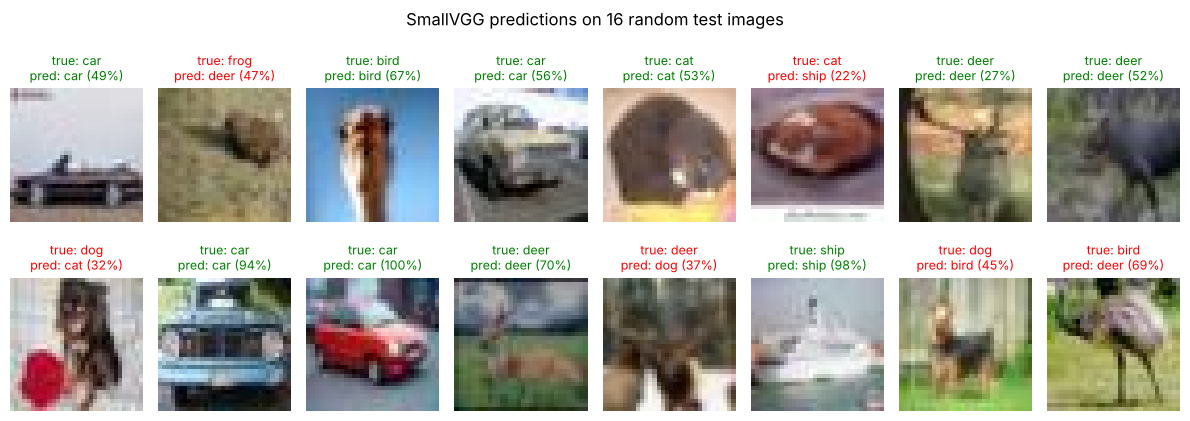

Predicted: car deer bird car
Truth:     car frog bird car


In [14]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize: correct here, because we normalised with mean 0.5, std 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

dataiter = iter(torch.utils.data.DataLoader(testset, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(1)))
images, labels = next(dataiter)
small.eval()
with torch.no_grad():
    probs = torch.softmax(small(images.to(device)), dim=1).cpu()
conf, predicted = probs.max(1)

plt.figure(figsize=(12, 4.6))
for k in range(16):
    plt.subplot(2, 8, k + 1)
    imshow(images[k])
    ok = predicted[k] == labels[k]
    plt.title(f"true: {classes[labels[k]]}\npred: {classes[predicted[k]]} ({conf[k]:.0%})", fontsize=9, color="green" if ok else "red")
plt.suptitle("SmallVGG predictions on 16 random test images"); plt.tight_layout(); plt.show()
print('Predicted:', ' '.join(f'{classes[predicted[j]]}' for j in range(4)))
print('Truth:    ', ' '.join(f'{classes[labels[j]]}' for j in range(4)))

### Save the model, load it back, and classify a single new image

A real classifier must work on images it has never seen. `torch.save(model.state_dict(), path)` stores only the learned numbers (not the code). To reload you build the same class and call `load_state_dict`. Below we classify an image from the CIFAR test set that is **not** part of our 1,000-image test subset (image number 999 of its class), and show the top-3 classes with probabilities.

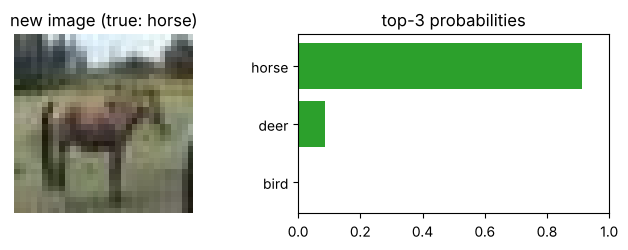

[('horse', 0.9125499129295349), ('deer', 0.08525834232568741), ('bird', 0.0011968696489930153)]


In [15]:
os.makedirs("data", exist_ok=True)
torch.save(small.state_dict(), "data/small_vgg_cifar10.pt")
model = SmallVGG()
model.load_state_dict(torch.load("data/small_vgg_cifar10.pt", map_location="cpu"))
model.eval()

def classify(pil_image, model, k=3):
    x = transform(pil_image.convert("RGB").resize((32, 32))).unsqueeze(0)   # same preprocessing as training, + batch dimension
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0]
    top = p.topk(k)
    return [(classes[i], float(v)) for v, i in zip(top.values, top.indices)]

# a held-out image (not in our test subset); on the official route we take test image 9999 instead
try:
    url = f"{MIRROR}/test/horse/0999.jpg"; path = "data/cifar10_jpg/extra_horse_0999.jpg"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    new_img, truth = Image.open(path), "horse"
except Exception:
    raw = torchvision.datasets.CIFAR10(root='./data', train=False, download=False)
    new_img, truth = raw[9999][0], classes[raw[9999][1]]

result = classify(new_img, model)
plt.figure(figsize=(7, 2.6))
plt.subplot(1, 2, 1); plt.imshow(new_img); plt.title(f"new image (true: {truth})"); plt.axis("off")
plt.subplot(1, 2, 2); plt.barh([c for c, _ in result][::-1], [p for _, p in result][::-1], color="C2")
plt.xlim(0, 1); plt.title("top-3 probabilities"); plt.tight_layout(); plt.show()
print(result)

## 4 · Two course bugs you can demonstrate: forgetting `eval()` and `no_grad()`

**`model.eval()`** switches two kinds of layer into "test behaviour":
- **Dropout** (VGG16 and SmallVGG both have it): in training mode it randomly zeroes 50 % of the neurons, so predictions become random-ish. In eval mode it does nothing.
- **BatchNorm**: in training mode it normalises with the statistics of the *current batch* and also **overwrites its stored running averages with test data**. In eval mode it uses the averages learned during training.

The course's test loop never calls `vgg16.eval()`, and since the training loop left the model in training mode, it tests with dropout on. Let's measure the damage on a copy of our trained SmallVGG.

One thing to know before reading the numbers: our test subset is stored **class by class** (100 planes, then 100 cars…), and `shuffle=False` keeps that order, so each test batch of 64 holds only one or two classes. In training mode BatchNorm normalises every batch by its own average, which here largely removes "what all these images have in common", i.e. the class. That makes the damage extra large. With **shuffled** test batches (last line) the damage is smaller but still real.

In [16]:
def accuracy_in_mode(model, train_mode):
    model.train(train_mode)
    correct = 0
    with torch.no_grad():
        for x, y in testloader:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return 100 * correct / len(testset)

m = copy.deepcopy(small)
print(f"with model.eval()          : {accuracy_in_mode(m, False):.2f}%")
print(f"without eval(), run 1      : {accuracy_in_mode(m, True):.2f}%")
print(f"without eval(), run 2      : {accuracy_in_mode(m, True):.2f}%   <- changes every run (dropout is random)")

# our test subset is stored class by class, so each test batch of 64 holds only 1-2 classes. Shuffle it:
m2 = copy.deepcopy(small); m2.train()
shuffled = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))
with torch.no_grad():
    correct = sum((m2(x.to(device)).argmax(1).cpu() == y).sum().item() for x, y in shuffled)
print(f"without eval(), shuffled test batches: {100 * correct / len(testset):.2f}%")
bn = small.features[1]
print(f"\nBatchNorm running mean changed by testing in train mode? {not torch.allclose(bn.running_mean, m.features[1].running_mean)}")

x = images[:4].to(device)
print("\nprediction WITHOUT torch.no_grad(): output.requires_grad =", small(x).requires_grad, "(a gradient graph was built for nothing)")
with torch.no_grad():
    print("prediction WITH    torch.no_grad(): output.requires_grad =", small(x).requires_grad)

with model.eval()          : 62.20%


without eval(), run 1      : 27.20%


without eval(), run 2      : 28.20%   <- changes every run (dropout is random)


without eval(), shuffled test batches: 56.30%

BatchNorm running mean changed by testing in train mode? True

prediction WITHOUT torch.no_grad(): output.requires_grad = True (a gradient graph was built for nothing)
prediction WITH    torch.no_grad(): output.requires_grad = False


## 5 · Visualising the VGG architecture (the course's Graphviz cell)

The course uses **torchviz** (`make_dot`) to draw the computation graph and `dot.render(...)` to save it as a PNG. Two things to know:
1. `pip install torchviz` installs only the Python part. **Rendering needs the Graphviz program** (`dot`) on your system: `sudo apt install graphviz` (Linux), `brew install graphviz` (Mac), or the installer from graphviz.org (Windows). On Colab it is already installed. Without it you get `ExecutableNotFound: failed to execute 'dot'`.
2. The torchviz graph of VGG16 is a very tall picture of every operation. For a viva, a **layer table** is usually more useful. `torchinfo.summary` prints each layer's output shape and parameter count.

The cell below tries the course's way first and falls back to `torchinfo` if Graphviz is missing (`pip install torchviz torchinfo`).

In [17]:
vgg16_vis = models.vgg16(weights=None)       # course: models.vgg16(pretrained=False)
x = torch.randn(1, 3, 224, 224)
try:
    from torchviz import make_dot
    from IPython.display import Image as IPImage, display
    y = vgg16_vis(x)
    dot = make_dot(y, params=dict(vgg16_vis.named_parameters()))
    dot.format = 'png'
    dot.render('data/vgg16_architecture')
    print("Graphviz is installed: diagram saved to data/vgg16_architecture.png")
    display(IPImage(filename='data/vgg16_architecture.png', width=300))
except Exception as e:
    print("torchviz could not render the diagram:", type(e).__name__, "-", str(e).split(chr(10))[0][:120])
    print("-> install the Graphviz system program to use the course's cell. Layer table instead:\n")

from torchinfo import summary
print(summary(vgg16_vis, input_size=(1, 3, 224, 224), col_names=("output_size", "num_params"), depth=2, verbose=0))

torchviz could not render the diagram: ExecutableNotFound - failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH
-> install the Graphviz system program to use the course's cell. Layer table instead:

Layer (type:depth-idx)                   Output Shape              Param #
VGG                                      [1, 1000]                 --
├─Sequential: 1-1                        [1, 512, 7, 7]            --
│    └─Conv2d: 2-1                       [1, 64, 224, 224]         1,792
│    └─ReLU: 2-2                         [1, 64, 224, 224]         --
│    └─Conv2d: 2-3                       [1, 64, 224, 224]         36,928
│    └─ReLU: 2-4                         [1, 64, 224, 224]         --
│    └─MaxPool2d: 2-5                    [1, 64, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 128, 112, 112]        73,856
│    └─ReLU: 2-7                         [1, 128, 112, 112]        --
│    └─Conv2d: 2-8                      

In [18]:
print(summary(SmallVGG(), input_size=(1, 3, 32, 32), col_names=("output_size", "num_params"), depth=2, verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
SmallVGG                                 [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 4, 4]            --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           64
│    └─ReLU: 2-3                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 32, 32]           9,248
│    └─BatchNorm2d: 2-5                  [1, 32, 32, 32]           64
│    └─ReLU: 2-6                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-7                    [1, 32, 16, 16]           --
│    └─Conv2d: 2-8                       [1, 64, 16, 16]           18,496
│    └─BatchNorm2d: 2-9                  [1, 64, 16, 16]           128
│    └─ReLU: 2-10                        [1, 64, 16, 16]           --
│    └─Conv2d: 2-11                      [1, 64, 16, 16]           36,928
│ 

In [19]:
print(f"Total run time of this notebook: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Total run time of this notebook: 8.2 minutes


## 🔧 What we changed from the course notebook, and why

| Course code | Our version | Why |
|---|---|---|
| `models.vgg16(pretrained=False)` | `models.vgg16(weights=None)` | `pretrained=` is deprecated in torchvision ≥ 0.13 (still works, prints a warning) |
| `CIFAR10(download=True)` only | official download first, **GitHub JPG mirror as fallback**, same 10 classes | the build machine cannot reach the Toronto server. The executed output above shows which route ran. |
| full 50,000 / 10,000 images | **500 / 100 per class** (`N_TRAIN_PER_CLASS`, `N_TEST_PER_CLASS`) | CPU time; change two numbers to use everything on a GPU |
| `Normalize((0.5,), (0.5,))` | kept (shown to equal `(0.5,0.5,0.5)`); new code uses the 3-value form | one value is silently reused for all 3 channels; the explicit form is clearer |
| VGG16 + Adam lr=0.001, 2 epochs | ran it for 1 epoch, **showed it stays at chance (10 %)**, then fix 1 (lr=0.0001) and fix 2 (SmallVGG with BatchNorm, augmentation, 15 epochs) | the course recipe does not learn; VGG16 is also 165× bigger than needed for 32×32 images |
| test loop without `model.eval()` | `evaluate()` calls `model.eval()` | dropout/BatchNorm must be in test mode (measured in section 4) |
| batch prediction without `torch.no_grad()` | wrapped in `torch.no_grad()` | no gradient graph needed for predictions |
| prints only 4 predicted labels | per-class accuracy, confusion matrix, 16-image grid with true/pred, single-image top-3 | a single accuracy number hides which classes fail |
| torchviz render (needs Graphviz) | tried first, `torchinfo.summary` fallback; files go to `data/` | Graphviz is a separate system program and is often missing |

## Results, honestly

Measured in the run above. CIFAR-10 subset: **5,000 training and 1,000 test images** (balanced), CPU only:

| Model | Epochs | Test accuracy | Parameters | Time per epoch (shared CPU) |
|---|---|---|---|---|
| **Course recipe:** VGG16 from scratch, Adam lr = 0.001 | 1 | **10.00 %** (chance) | 134.3 M | about 134 s |
| Fix 1: same VGG16, Adam lr = 0.0001 | 1 | **17.50 %** | 134.3 M | about 138 s |
| Fix 2: SmallVGG (3×3 convs + BatchNorm + augmentation), Adam lr = 0.001, cosine schedule | 15 | **62.20 %** | 0.82 M | about 11 s |
| chance (guessing) | | 10 % | | |

What this shows:
- **The course's VGG16 recipe does not learn at all.** After a burst of huge losses in the first batches, every ReLU at the end of the conv layers was dead, every image got the same scores, and all 1,000 test images were predicted as one class. This is a real, common failure of deep plain networks with a too-large learning rate, not a coding bug.
- **A 10× smaller learning rate gets VGG16 learning** (17.50 % after one epoch), but it is slow: each epoch took minutes on a CPU, and its predictions after one epoch are still very lopsided (it predicts only a few classes; see the counts above).
- **A small network designed for 32×32 images wins easily**: 62.20 % with **165× fewer parameters**, and each epoch was several times faster. Its curve was still rising at the end, so more epochs or more data would push it higher.
- **Hardest classes** (per-class accuracy): cat, deer and bird; the most common mistake was **dog → cat**. Easiest: car, ship, truck and frog.
- **Forgetting `model.eval()`** cost a lot: 62.20 % with `eval()` vs 27.20 % / 28.20 % without it (two runs, different each time), and 56.30 % with shuffled test batches. The size of the drop depends on how the test batches are composed, which is exactly why you must call `eval()`.
- **Data route:** the official CIFAR-10 download was blocked on the build machine, so the GitHub JPG mirror was used. On your machine you will probably get the official route and a different (but equally balanced) set of 500 + 100 images per class, so your numbers will differ by a few points.
- **Not measured here:** the full 50,000-image training set, more epochs, and a pretrained VGG16. Those are GPU experiments; see *Try this yourself* and the Colab section.

## Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `RuntimeError: Expected all tensors to be on the same device ... cuda:0 and cpu` | model on GPU, data on CPU (or the other way round) | `.to(device)` on **both** the model and every batch (`inputs.to(device), labels.to(device)`) |
| `CUDA out of memory` | batch too big for the GPU (VGG16 at 224×224 is huge) | smaller `batch_size` (64 → 32 → 16); `torch.no_grad()` when testing; `torch.cuda.empty_cache()` |
| loss stuck at **2.303** and accuracy ≈ 10 % | network collapsed to a constant guess (as in section 2.3) | lower the learning rate, use a BatchNorm model (`vgg16_bn`, SmallVGG), check the data and labels |
| `RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x2048 and 4096x10)` | a `Linear` layer's input size does not match the previous layer's output | print the shape before the layer (`x.shape`) or use `torchinfo.summary`; for VGG16 the new last layer must be `nn.Linear(4096, 10)` |
| accuracy changes every time you test / lower than expected | forgot `model.eval()` (dropout still on) | call `model.eval()` before testing and `model.train()` before training |
| images look washed-out or too dark when plotted | displayed normalised values | undo the normalisation: `img * std + mean` (here `img / 2 + 0.5`) |
| `URLError` / `HTTP Error 403` when downloading CIFAR-10 | no internet or blocked server | the notebook falls back to the GitHub mirror automatically |
| `ExecutableNotFound: failed to execute 'dot'` | Graphviz program not installed | `apt install graphviz` / `brew install graphviz`, or use `torchinfo.summary` |
| `UserWarning: The parameter 'pretrained' is deprecated` | old torchvision API | use `weights=None` or `weights=models.VGG16_Weights.DEFAULT` |

## Try this yourself

1. **Course recipe, 2 epochs.** Change `range(1, 2)` back to `range(1, 3)` in section 2.3. Does the loss ever leave 2.303?
2. **VGG16 with batch-norm.** Replace `models.vgg16` by `models.vgg16_bn(weights=None)` and keep lr = 0.001. Does BatchNorm alone fix the collapse?
3. **Pretrained VGG16.** `models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)`, resize CIFAR images to 224 (`transforms.Resize(224)`), freeze `features` and train only the classifier. This is transfer learning (Lab 2). Use a GPU.
4. **No augmentation.** Train SmallVGG with the plain `transform`. Compare training loss and test accuracy: is the gap (overfitting) bigger?
5. **More data.** Set `N_TRAIN_PER_CLASS = 2000`. How much does test accuracy improve?
6. **Remove BatchNorm** from `conv_bn_relu`. Does SmallVGG still train with lr = 0.001?
7. **Your own photo.** `classify(Image.open("my_cat.jpg"), model)`. Remember that it was trained on 32×32 thumbnails, so centred, uncluttered objects work best.

## Run it on Google Colab with a GPU

1. Upload this notebook to [colab.research.google.com](https://colab.research.google.com) (File → Upload notebook).
2. **Runtime → Change runtime type → T4 GPU**, then Save.
3. Run `!pip install torchinfo torchviz` in a new first cell (everything else is pre-installed).
4. Delete the `torch.set_num_threads(2)` line. `device` will print `cuda`.
5. For the real experiment set `N_TRAIN_PER_CLASS = 5000`, `N_TEST_PER_CLASS = 1000` and the course's `range(1, 3)`. The official CIFAR-10 download will work there, so the output will say `DATA ROUTE: official`.
6. Expect the numbers to differ from ours: more data gives higher accuracy for every model.

## Viva questions (with short model answers)

1. **What is CIFAR-10?** 60,000 colour images of 32×32 pixels in 10 balanced classes: 50,000 train and 10,000 test.
2. **What do `ToTensor()` and `Normalize((0.5,),(0.5,))` do?** `ToTensor` converts the image to a C×H×W float tensor in [0, 1]. `Normalize` computes (x − 0.5)/0.5 → [−1, 1]. The single value is applied to all 3 channels.
3. **Why replace `vgg16.classifier[6]`?** It is the last layer, with 1000 outputs for ImageNet. CIFAR-10 has 10 classes, so we need `nn.Linear(4096, 10)`.
4. **What does `pretrained=False` / `weights=None` mean?** Random initial weights, so the network is trained from scratch. `weights=VGG16_Weights.DEFAULT` loads ImageNet-trained weights.
5. **What is CrossEntropyLoss and what is its value for a random guess on 10 classes?** Softmax + negative log-likelihood of the true class. A uniform guess gives −ln(1/10) ≈ 2.303.
6. **Explain `zero_grad`, `backward`, `step`.** Clear the old gradients (they accumulate), compute new gradients by backpropagation, update the weights with the optimiser.
7. **Why did the course's VGG16 stay at 10 %?** Deep plain network (no BatchNorm) with random weights and a learning rate too big for it. Activations die, so it outputs a constant guess and the gradients vanish. Fix: lower lr, BatchNorm (`vgg16_bn`), a smaller net, or pretrained weights.
8. **What does VGG16 do with a 32×32 input?** Five 2× pools give a 1×1×512 map. `AdaptiveAvgPool2d(7,7)` copies it to 7×7, so the 25,088-input FC layer sees 512 distinct numbers. It works, but it is wasteful.
9. **Why 3×3 filters in VGG?** Stacked 3×3 convs give a large receptive field (two → 5×5, three → 7×7) with fewer parameters and more non-linearities than one large filter.
10. **What is an epoch, a batch, batch size?** Batch = the images processed together before one weight update (64 here). Epoch = one full pass over the training set (`len(trainloader)` batches).
11. **Why `model.eval()` and `torch.no_grad()` when testing?** `eval()` turns off dropout and makes BatchNorm use its stored statistics (we measured the accuracy dropping and changing without it). `no_grad()` skips building the gradient graph: faster and less memory.
12. **What does `torch.max(outputs, 1)` return?** The maximum score and its index along the class dimension. The index is the predicted class.
13. **What does BatchNorm do and why did it help?** It normalises each channel's activations over the batch and then rescales them with learned parameters. This keeps signals at a healthy scale, so deep nets train stably with larger learning rates.
14. **What is data augmentation?** Random, label-preserving changes (shifts, flips) applied to training images on the fly. The model sees more variety, so it overfits less. It is never applied to test images.
15. **Which classes are hardest and why?** Look at the per-class accuracy and confusion matrix above. In our run cat, deer and bird were hardest; the most common mistake was dog ↔ cat, and planes were confused with ships (both often on a plain blue background). Animals look alike at 32×32 pixels; cars, trucks and ships have more distinctive shapes and colours.